# Вероятности исходов матчей

[Отчёт](../reports/report.md) · [PDF](../reports/report.pdf)

## Подготовка

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from match_forecast.__main__ import run

_ = run(ROOT, train=False)
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
predictions = pd.read_csv(REPORTS / 'final_predictions.csv')
metrics = pd.read_csv(REPORTS / 'tables/final_model_metrics.csv')
configuration = json.loads((ROOT / 'config/report_model.json').read_text(encoding='utf-8'))
display(pd.Series(configuration))

kind                            match
model            dense_32_16_ensemble
training                    expanding
probabilities                     raw
evaluation              retrospective
profile                   regularized
dtype: object

## Лиги и обучение

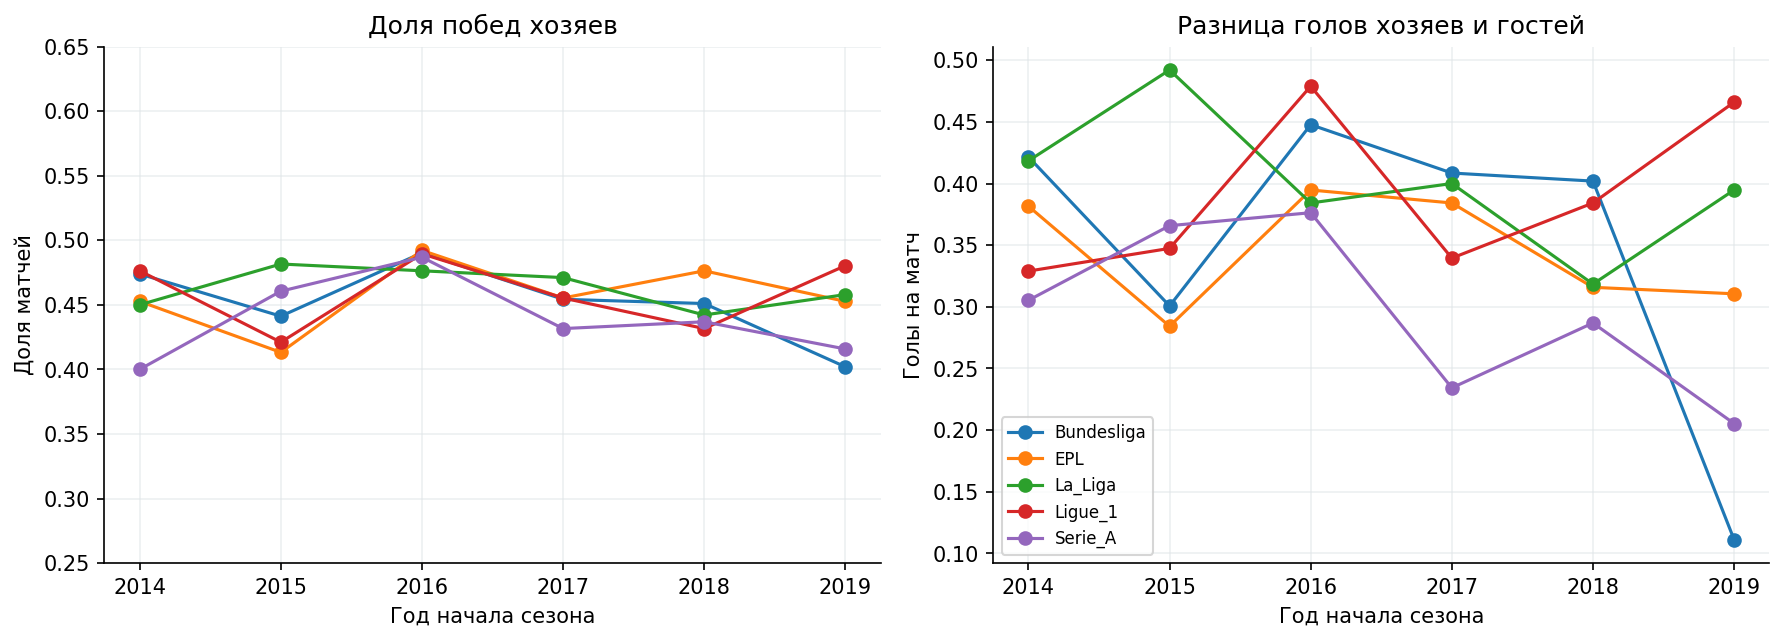

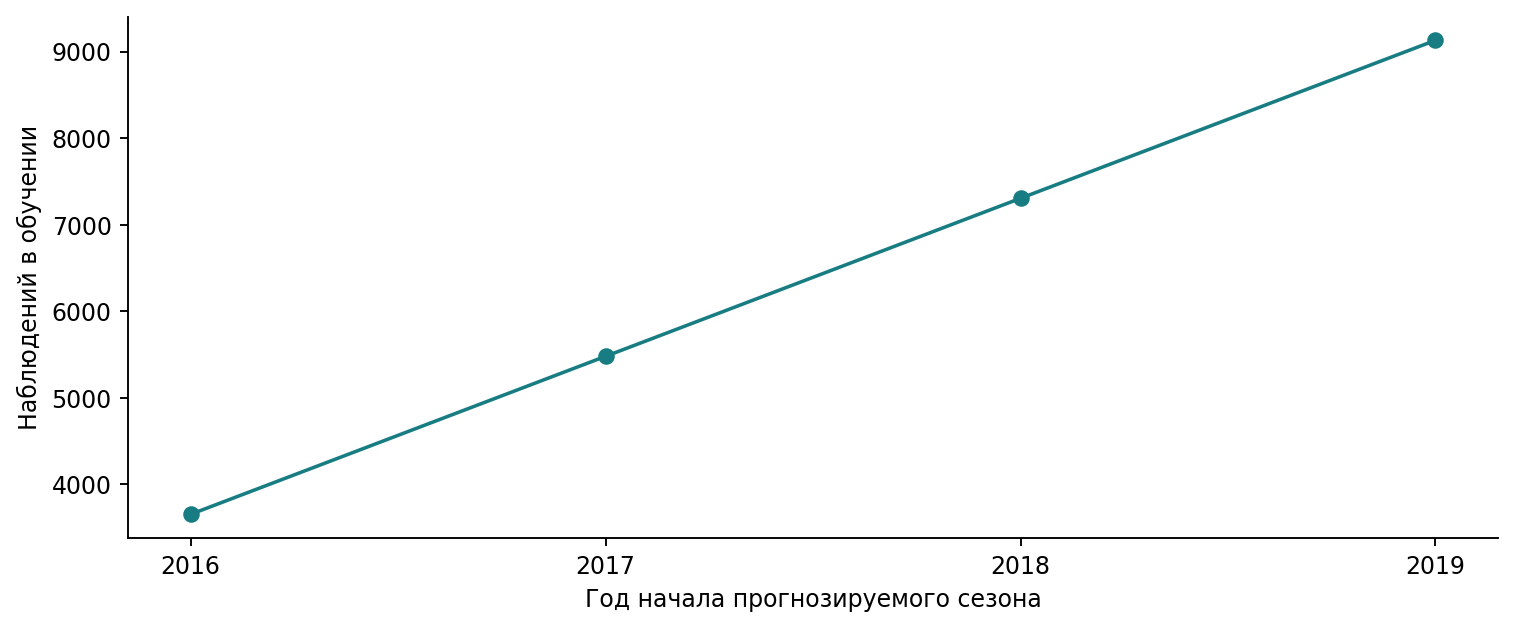

In [2]:
display(Image(filename=str(FIGURES / 'home_advantage.png'), width=1000))
display(Image(filename=str(FIGURES / 'final_training_window.png'), width=950))

## Качество вероятностей

n           1725.000000
log_loss       0.991866
brier          0.591309
accuracy       0.514203
dtype: float64

,model,group,n,log_loss,brier,accuracy
0,constant,all,1725,1.070456,0.647669,0.441159
8,elo,all,1725,1.004276,0.600039,0.517101
16,poisson,all,1725,1.025790,0.615207,0.489855
24,neural,all,1725,0.991866,0.591309,0.514203


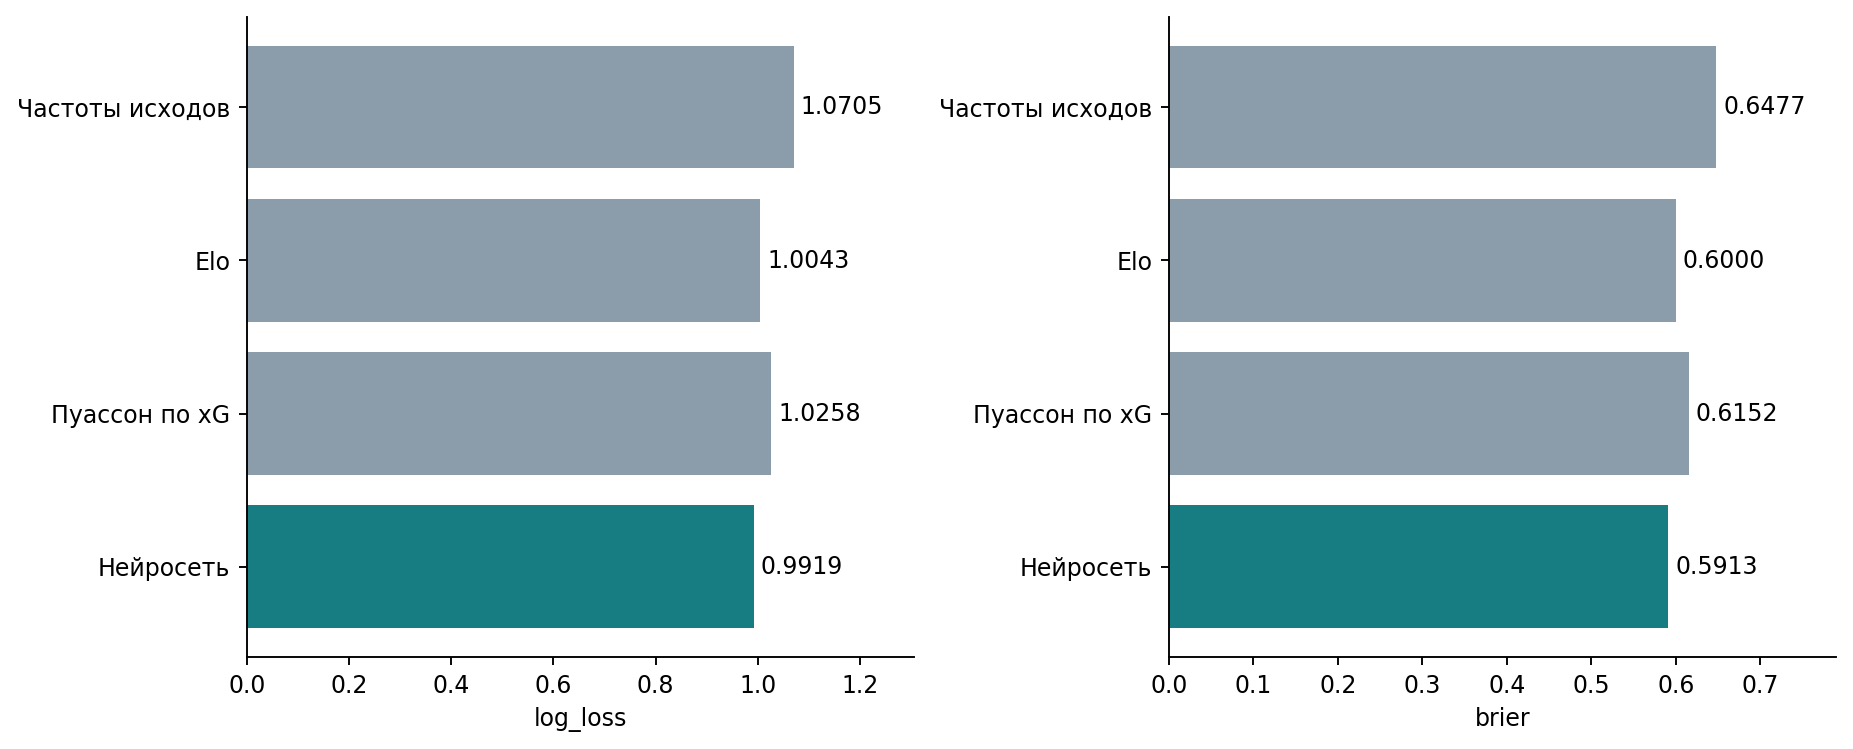

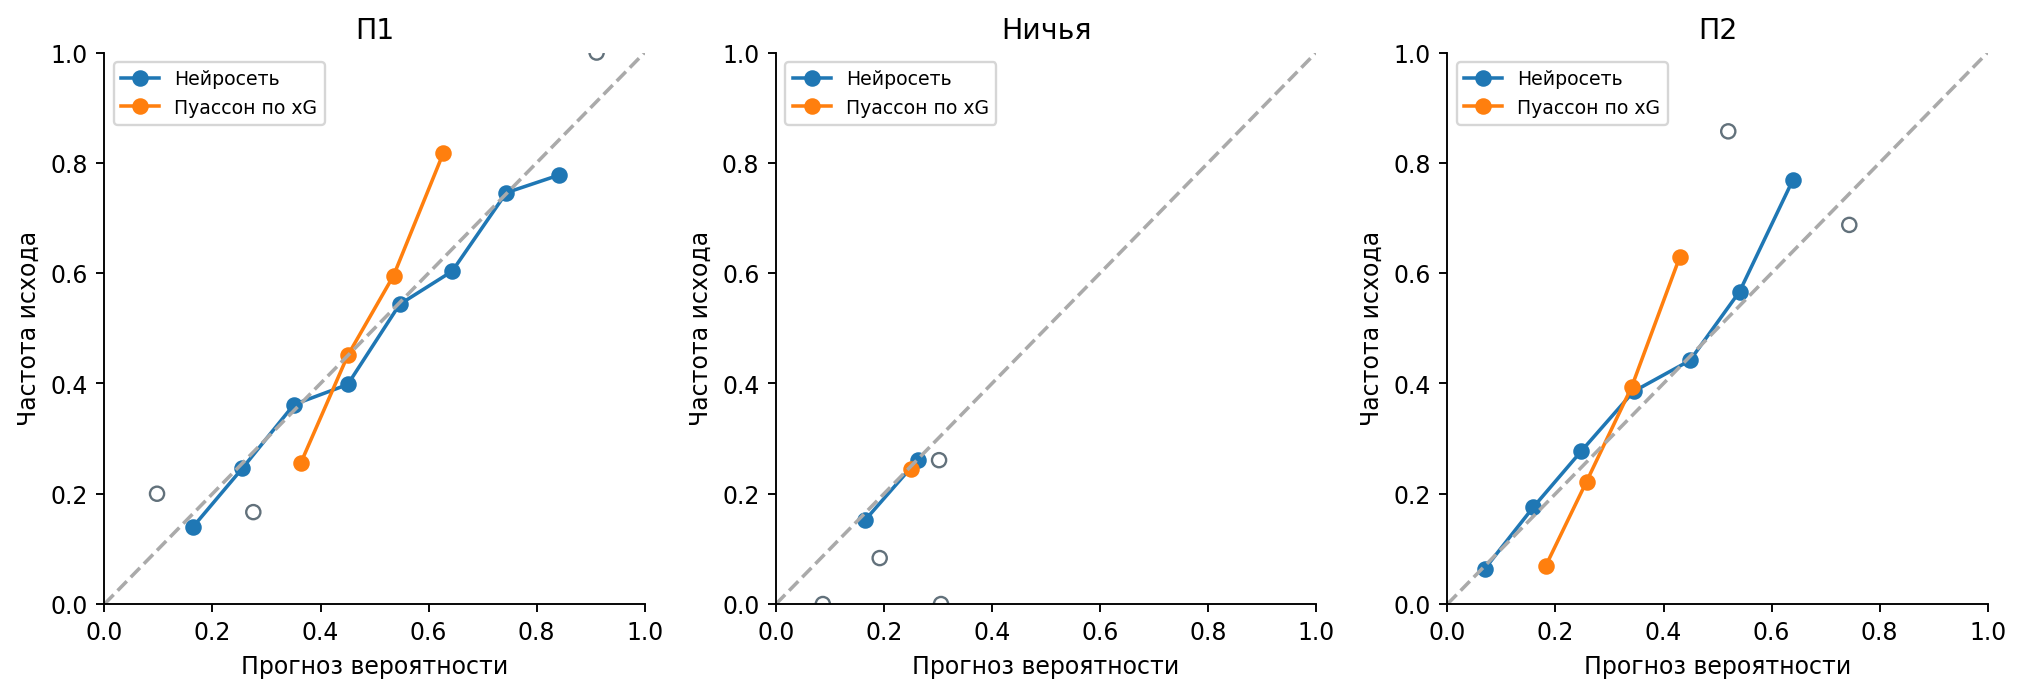

In [3]:
from match_forecast.common import scores

p = predictions[['p_neural_0', 'p_neural_1', 'p_neural_2']].to_numpy()
display(pd.Series(scores(predictions.target.to_numpy(int), p)))
display(metrics.loc[metrics.group.eq('all')])
display(Image(filename=str(FIGURES / 'final_model_quality.png'), width=1050))
display(Image(filename=str(FIGURES / 'final_probability_check.png'), width=1050))

## Ошибки и сравнение моделей

,baseline,difference,low,high,clusters
0,constant,-0.078591,-0.095332,-0.062164,41
1,elo,-0.012411,-0.020661,-0.003745,41
2,poisson,-0.033925,-0.044587,-0.023682,41


,model,group,n,log_loss,brier,accuracy
24,neural,all,1725,0.991866,0.591309,0.514203
25,neural,Bundesliga,306,0.995563,0.594386,0.506536
26,neural,EPL,380,0.978389,0.581392,0.510526
27,neural,La_Liga,380,1.008755,0.605406,0.497368
28,neural,Ligue_1,279,1.000925,0.599248,0.505376
29,neural,Serie_A,380,0.978824,0.578822,0.547368
30,neural,До перерыва,1317,1.000260,0.597457,0.509491
31,neural,После перерыва,408,0.964769,0.571462,0.529412


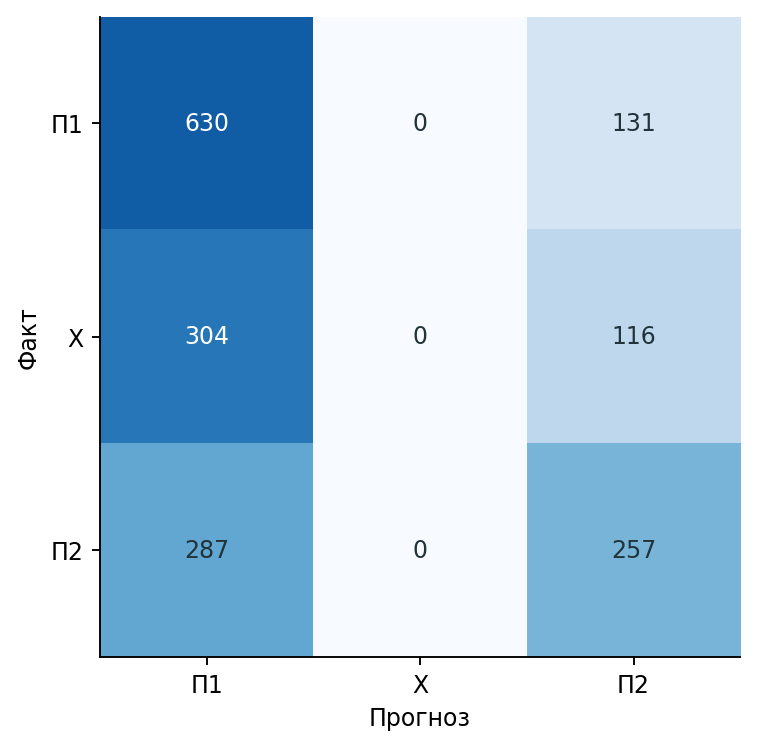

In [4]:
display(pd.read_csv(REPORTS / 'tables/final_model_comparison.csv'))
display(metrics.loc[metrics.model.eq('neural')])
display(Image(filename=str(FIGURES / 'final_confusion.png'), width=700))

## Матчи и ожидаемые очки

In [5]:
MATCH_ID = None
example = predictions.loc[predictions.match_id.eq(MATCH_ID)] if MATCH_ID else predictions.sort_values('date').tail(10)
display(example[['match_id','date','home','away','p_neural_0','p_neural_1','p_neural_2']])
teams = pd.read_csv(REPORTS / 'tables/final_team_points.csv')
display(teams.sort_values('difference', ascending=False).head(10))

,match_id,date,home,away,p_neural_0,p_neural_1,p_neural_2
1719,13467,2020-08-01,Juventus,Roma,0.621563,0.230004,0.148433
1715,13459,2020-08-01,Atalanta,Inter,0.495514,0.279659,0.224827
1716,13462,2020-08-01,Napoli,Lazio,0.534432,0.270372,0.195196
1717,13464,2020-08-01,AC Milan,Cagliari,0.752783,0.168221,0.078996
1718,13465,2020-08-01,Brescia,Sampdoria,0.360972,0.284412,0.354616
1722,13463,2020-08-02,Bologna,Torino,0.455231,0.290585,0.254185
1723,13466,2020-08-02,Genoa,Verona,0.409591,0.292221,0.298189
1720,13460,2020-08-02,SPAL 2013,Fiorentina,0.318758,0.272764,0.408478
1721,13461,2020-08-02,Sassuolo,Udinese,0.482571,0.280945,0.236484
1724,13468,2020-08-02,Lecce,Parma Calcio 1913,0.487541,0.269231,0.243228


,league,team,matches,points,expected,difference
27,EPL,Liverpool,38,99,83.897366,15.102634
87,Serie_A,Lazio,38,78,62.976685,15.023315
52,La_Liga,Real Madrid,38,87,74.845108,12.154892
46,La_Liga,Granada,38,56,44.336548,11.663452
65,Ligue_1,Marseille,28,56,44.798958,11.201042
74,Ligue_1,Rennes,28,50,40.797312,9.202688
50,La_Liga,Osasuna,38,52,42.815900,9.184100
4,Bundesliga,Borussia M.Gladbach,34,65,56.372691,8.627309
8,Bundesliga,Freiburg,34,48,39.861492,8.138508
32,EPL,Sheffield United,38,54,45.981550,8.018450
